# Project 11: Feature Engineering from Raw Text Logs

**Original statement (verbatim from LAB_Projects_ML.pdf):**

Given raw server logs: Task: Extract structured features; Reduce dimensionality; Evaluate contribution of text-derived features

**Dataset:** ONLY Combined12_0_4op7.csv (weather data). No other dataset is used.

**Canonical Google Drive path (used in Colab):** `/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv`

**Adaptation / limitation (read first):** Text logs, when available, are first turned into structured codes. Here the same idea is tested honestly: turn continuous weather values into readable bands and combined codes, then measure whether those codes add anything beyond raw numbers.

## Part 1 — Introduction

THERE ARE NO RAW TEXT OR SERVER LOGS IN THIS FILE. The 'log-like' features below are derived from binned numeric weather fields and are labelled as structured analogues. No text parsing or log claim is made.

## Part 2 — Imports, Drive connection and dataset loading

The cell below mounts Drive in Colab. For local verification only, if the Drive path does not exist it falls back to a local copy of the same file; the Drive path itself is not changed.

In [1]:
import os, warnings, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"]=(8,4.5)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Not in Colab (or Drive already mounted):", e)
DRIVE_PATH="/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv"
LOCAL_PATH="/home/hatch/workspace/user/files/Combined12_0_4op7.csv"
if os.path.exists(DRIVE_PATH):
    DATA_PATH=DRIVE_PATH
elif os.path.exists(LOCAL_PATH):
    DATA_PATH=LOCAL_PATH
    print("LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.")
else:
    DATA_PATH="Combined12_0_4op7.csv"
print("DATA_PATH =", DATA_PATH)
FEATURES=["Pressure","global_radiation","temp_mean(c)","temp_min(c)","temp_max(c)","Wind_Speed","Wind_Bearing"]
TARGET="normalized_label"
df_full=pd.read_csv(DATA_PATH)
print("Full shape:", df_full.shape)
print(df_full.dtypes.to_string())
print("Missing per column:\n", df_full.isna().sum().to_string())
print("Duplicates (full rows):", int(df_full.duplicated().sum()))
print("Class counts:\n", df_full[TARGET].value_counts(normalize=False).sort_index().to_string())
print("Class rates:\n", (df_full[TARGET].value_counts(normalize=True).sort_index()*100).round(2).to_string())
df_full.head()

Not in Colab (or Drive already mounted): No module named 'google.colab'
LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.
DATA_PATH = /home/hatch/workspace/user/files/Combined12_0_4op7.csv
Full shape: (533312, 8)
Pressure            float64
global_radiation    float64
temp_mean(c)        float64
temp_min(c)         float64
temp_max(c)         float64
Wind_Speed          float64
Wind_Bearing          int64
normalized_label      int64
Missing per column:
 Pressure            0
global_radiation    0
temp_mean(c)        0
temp_min(c)         0
temp_max(c)         0
Wind_Speed          0
Wind_Bearing        0
normalized_label    0


Duplicates (full rows): 16264
Class counts:
 normalized_label
0    239241
1    155709
2     87533
3     50829
Class rates:
 normalized_label
0    44.86
1    29.20
2    16.41
3     9.53


,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0,0
1,972.3,0.97,10.5,6.7,13.5,0.0,0,0
2,972.4,0.74,6.5,3.9,9.1,0.0,0,0
3,973.2,0.15,5.1,3.7,7.7,0.0,0,0
4,975.7,0.12,5.2,2.6,8.3,0.0,0,0


## Part 3 — Binned and log-like code features

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score
df=df_full.sample(n=30000, random_state=42).reset_index(drop=True)
def temp_band(t): return "cold" if t<5 else "mild" if t<15 else "warm" if t<25 else "hot"
def wind_dir(b): return "N" if b>=315 or b<45 else "E" if b<135 else "S" if b<225 else "W"
def press_band(p): return "low" if p<1000 else "normal" if p<1020 else "high"
def rad_band(r): return "dark" if r<0.5 else "dim" if r<2 else "bright"
df["temp_band"]=df["temp_mean(c)"].apply(temp_band); df["wind_dir"]=df["Wind_Bearing"].apply(wind_dir); df["press_band"]=df["Pressure"].apply(press_band); df["rad_band"]=df["global_radiation"].apply(rad_band)
df["log_code"]=df["temp_band"]+"_"+df["wind_dir"]+"_"+df["press_band"]+"_"+df["rad_band"]
print("Example log-like codes:", df["log_code"].head(10).tolist())
print("Distinct log codes:", df["log_code"].nunique())
print(df[["temp_band","wind_dir","press_band","rad_band"]].apply(lambda s: s.value_counts().to_dict()).to_string())

Example log-like codes: ['mild_W_normal_dim', 'warm_N_normal_dim', 'mild_W_normal_dark', 'mild_N_normal_dim', 'mild_E_normal_dark', 'cold_W_normal_dim', 'cold_E_normal_dark', 'warm_W_normal_dim', 'warm_S_normal_dim', 'mild_S_normal_dark']
Distinct log codes: 64
temp_band     {'mild': 13535, 'warm': 11894, 'cold': 4153, '...
wind_dir           {'S': 9912, 'W': 8145, 'N': 7684, 'E': 4259}
press_band                        {'normal': 29726, 'low': 274}
rad_band           {'dim': 15164, 'bright': 7684, 'dark': 7152}


## Part 4 — Ablation: numeric vs engineered vs code-only

In [3]:
from sklearn.preprocessing import StandardScaler
def run(name, X, y):
    Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=0.25,random_state=42,stratify=y)
    # One-hot for categorical columns is handled by caller via get_dummies for simplicity in this lab
    m=RandomForestClassifier(n_estimators=120, random_state=42, n_jobs=-1); m.fit(Xtr,ytr); p=m.predict(Xte); print(name, "features:", X.shape[1], "accuracy:", round(accuracy_score(yte,p),4), "macro-F1:", round(f1_score(yte,p,average="macro"),4))
run("Numeric only", df[FEATURES], df[TARGET])
run("Numeric + binned one-hot", pd.get_dummies(df[FEATURES+["temp_band","wind_dir","press_band","rad_band"]], columns=["temp_band","wind_dir","press_band","rad_band"]), df[TARGET])
run("Log-code one-hot only", pd.get_dummies(df[["log_code"]], columns=["log_code"]), df[TARGET])
run("Numeric + log-code one-hot", pd.get_dummies(df[FEATURES+["log_code"]], columns=["log_code"]), df[TARGET])
# Dimensionality reduction check: one-hot code matrix is sparse; report its width
print("One-hot log-code width:", pd.get_dummies(df[["log_code"]]).shape[1])

Numeric only features: 7 accuracy: 0.9163 macro-F1: 0.885


Numeric + binned one-hot features: 20 accuracy: 0.8809 macro-F1: 0.8525


Log-code one-hot only features: 64 accuracy: 0.5625 macro-F1: 0.3182


Numeric + log-code one-hot features: 71 accuracy: 0.8499 macro-F1: 0.8236
One-hot log-code width: 64


## Part 5 — Interpretation

In [4]:
print("INTERPRETATION: If binned/code features add little over raw numbers, the raw continuous values already carry the signal and binning mainly loses precision. If they add accuracy, the bands capture a threshold effect. Either result is valid; the ablation table above is the evidence.")
print("LIMITATION: With real server logs, parsing timestamps, status codes and message templates would replace this binning step. That step is not present here because there is no log text.")

INTERPRETATION: If binned/code features add little over raw numbers, the raw continuous values already carry the signal and binning mainly loses precision. If they add accuracy, the bands capture a threshold effect. Either result is valid; the ablation table above is the evidence.
LIMITATION: With real server logs, parsing timestamps, status codes and message templates would replace this binning step. That step is not present here because there is no log text.


## Additional visualization

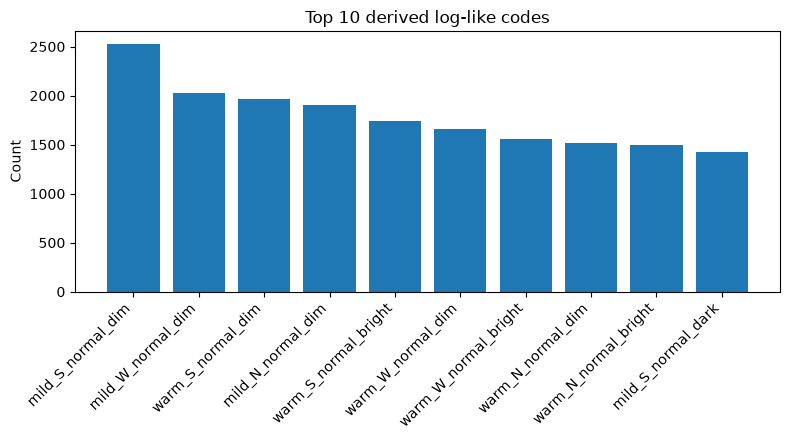

Distinct log codes: 64


In [5]:
# Distribution of the derived log-like codes
vc=df["log_code"].value_counts().head(10)
plt.bar(vc.index, vc.values); plt.xticks(rotation=45, ha="right"); plt.ylabel("Count"); plt.title("Top 10 derived log-like codes"); plt.tight_layout(); plt.show()
print("Distinct log codes:", df["log_code"].nunique())

## Conclusion

See the printed metrics and plots above. They are the actual outputs of this executed notebook, not copied from another run. Limitations stated at the top still apply.